# 1.1 · Loading a bond index's constituents

> **Needs:** a SQL Server database migrated to the latest schema (equity notebook 1.1 does that, or `uv run alembic upgrade head`), and a folder of ICE's month-end constituent files named in `EQR_ICE_DIR` (or in `FOLDER` below).
>
> **Produces:** the bonds, their issuers, each index's monthly members and weights, the bonds' monthly analytics and the index's official level in the database, and the local fixed income research cache that notebook 2.1 reads.

A **bond index** is a portfolio of bonds defined by rules - which bonds qualify, and each one's weight (its market
value). ICE Data Indices publishes, for every index and every month end, the list of its **constituents** with what
it knows of each bond that day. The **ICE BofA US High Yield Index** (`H0A0`) is the US dollar market for bonds
rated below investment grade; it is the first index loaded here.

Each file is one index on one month end, named `<index>-<MMDDYYYY>.xlsx`, one row per bond:

| What | Columns | Kept in |
|---|---|---|
| **Who the bond is** | CUSIP, ISIN, description, currency | `core.listing` (a bond is a listing), `core.identifier` |
| **Who issued it** | ICE's ticker, country, four industry levels | `core.issuer`, `fixed_income.issuer_classification` |
| **Its terms and rating** | coupon, maturity, subordination, composite rating | `fixed_income.bond_analytics` |
| **Its price and yield** | price, accrued interest, yields to worst and to maturity, effective yield | `fixed_income.bond_analytics` |
| **Its spread** | option-adjusted spread (OAS), asset-swap spread, in basis points | `fixed_income.bond_analytics` |
| **Its interest-rate and spread risk** | effective and modified duration, spread duration, convexity | `fixed_income.bond_analytics` |
| **Its return over the month** | total return, and excess return over duration-matched government bonds | `fixed_income.bond_analytics` |
| **Its place in the index** | weight, the weight a month before, face value | `fixed_income.index_constituent` |

Three things about these files shape everything that follows:

1. **The universe is next month's.** ICE rebalances its indices on the last calendar day of the month. The file
   dated 31 January therefore lists the index's members *for February*, each with its price, analytics and
   *January* return as of that day. A bond's weight during February is the January file's weight.
2. **A bond that leaves takes its last month with it.** A bond that matured, was called, was upgraded out of high
   yield or defaulted during February is not in the February file - so its February return is in no file. A
   quality check below measures how much of the index that is each month.
3. **An issuer is ICE's ticker.** ICE files a company and its financing subsidiaries under one ticker
   (*Alcoa Nederland Holding B.V.* under `AA`). The ticker is the issuer here; each bond keeps its own legal name.
   The industry levels and the country are stored per issuer and month.

As for the equity data (equity notebook 1.1), every file is first copied unchanged into the **raw zone** and
registered as a batch, every row written names its batch, and writes are change-only - so the load can be run as
often as files arrive, in any order.

In [1]:
import logging
import os
from pathlib import Path

import pandas as pd
from IPython.display import display

from fixed_income_research.pipelines.load_ice import FOLDER_SETTING, constituent_files, load_ice
from research_core.data.db.engine import get_engine
from research_core.settings import get_settings

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

logging.basicConfig(level=logging.WARNING, format="%(asctime)s  %(message)s", datefmt="%H:%M:%S", force=True)

FOLDER = None  # the folder of ICE's files; None: the folder named by EQR_ICE_DIR

settings = get_settings()
engine = get_engine()
folder = Path(FOLDER or os.environ[FOLDER_SETTING])
files, refused = constituent_files(folder)
months = pd.Series([as_of for _, as_of, _ in files])
print("Database:", settings.database.name)
codes = sorted({code for code, _, _ in files})
print(f"{len(files)} constituent files of {codes}, {months.min():%B %Y} to {months.max():%B %Y}")
print("Files that cannot be read as constituent files:", refused or "none")

Database: quant_research_local
90 constituent files of ['H0A0'], January 2019 to July 2026
Files that cannot be read as constituent files: none


## Step 1 · Load the files

One call lands and loads every file not loaded before. `loaded` counts the files read now, `already_loaded` those
skipped; `bonds_created` and `issuers_created` are new rows in the security master. `issuers_disagreeing` counts
the issuer-months whose bonds named more than one sub-industry or country - the issuer then takes that of its
largest bond. `identifier_conflicts` are CUSIPs another security already holds: reported, never reassigned.

In [2]:
report = load_ice(engine, folder)
display(pd.Series({k: v for k, v in report.items() if not isinstance(v, dict)}, name="files and identities").to_frame())
display(pd.DataFrame({k: report[k] for k in ("analytics", "constituents", "issuer_months")}).T)

,files and identities
files,90
loaded,90
already_loaded,0
bonds_created,5459
issuers_created,1704
identifier_conflicts,2
issuers_disagreeing,221


,inserted,updated
analytics,172995,0
constituents,172995,0
issuer_months,79081,0


## Step 2 · The index's official level

A rebuilt index is judged against the real one. FRED (the Federal Reserve Bank of St. Louis) publishes the
total-return level of ICE's headline indices, free - but only the last three years of it. Each finished month's
last level is stored, so months loaded now stay when FRED drops them: run this step every month.

In [3]:
from fixed_income_research.pipelines.load_index_levels import load_index_levels

display(pd.DataFrame(load_index_levels(engine)).T)

,months,inserted,updated
C0A0,36,36,0
H0A0,36,36,0


## Step 3 · Data-quality checks

Each check measures one number and compares it with a *warn* level (look into it) and a *fail* level (stop).

| Check | What it measures |
|---|---|
| `bond_index_weights_sum_to_100` | share of index months whose weights add up to 100 % - a file loaded in part does not |
| `bond_index_missing_months` | month ends with no file between an index's first and last: that month's return cannot be rebuilt, nor the next month's |
| `bond_constituents_without_analytics` | index members with no analytics on the same day |
| `bonds_without_issuer` | bonds not linked to an issuer |
| `held_bonds_without_return` | share of the weight held through a month, and still in the index, that has no return for it |
| `bond_index_weight_leaving_without_return` | average percent of an index that leaves at a rebalance, its last month's return in no file |
| `bond_rows_without_provenance` | rows that do not name the raw file they came from |

In [4]:
from fixed_income_research.quality.checks import BOND_CHECKS
from research_core.data.quality import run_checks

results = run_checks(engine, BOND_CHECKS)
display(pd.DataFrame([{"check": r.name, "status": r.status, "value": r.value, "levels": r.threshold} for r in results]))

,check,status,value,levels
0,bond_index_weights_sum_to_100,pass,1,"warn >= 1.0, fail >= 0.99"
1,bond_index_missing_months,warn,1,"warn <= 0, fail <= 24"
2,bond_constituents_without_analytics,pass,0,"warn <= 0, fail <= 0"
3,bonds_without_issuer,pass,0,"warn <= 0, fail <= 0"
4,held_bonds_without_return,pass,0,"warn <= 0.005, fail <= 0.05"
5,bond_index_weight_leaving_without_return,pass,1.881,"warn <= 3.0, fail <= 10.0"
6,bond_rows_without_provenance,pass,0,"warn <= 0, fail <= 0"


## Step 4 · Sync the research cache

Research reads a local copy of the tables (Parquet files queried with DuckDB), as the equity research does. The
fixed income cache has a folder of its own, so loading bonds never makes the equity research's stored results
stale.

In [5]:
from fixed_income_research.data.cache import ResearchCache

cache = ResearchCache()
display(pd.Series(cache.sync(engine), name="rows copied").to_frame())

,rows copied
core.vendor,11
core.issuer,6882
core.listing,10795
core.identifier,45796
fixed_income.index_definition,2
fixed_income.index_level,72
fixed_income.index_constituent,172995
fixed_income.bond_analytics,172995
fixed_income.issuer_classification,79081


## What was loaded

The number of bonds in each index on every month end, and the months with no file.

Month ends with no file: ['2025-04']


as_of_date,2019-12-31,2020-12-31,2021-12-31,2022-12-31,2023-12-31,2024-12-31,2025-12-31,2026-12-31
code,,,,,,,,
H0A0,"1,775","2,030","2,123","1,927","1,837","1,879","1,922","1,890"


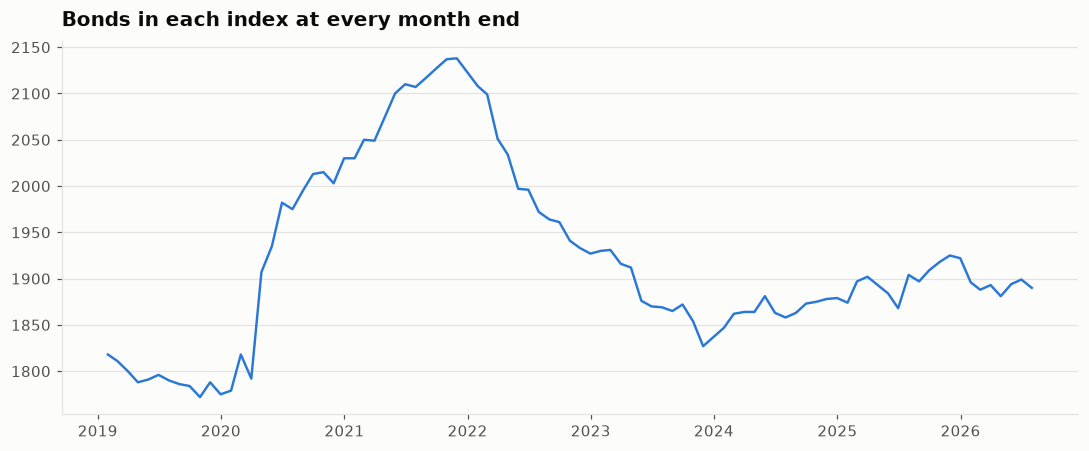

In [6]:
from research_core import charts

charts.style()
counts = cache.query(
    "SELECT i.code, c.as_of_date, COUNT(*) AS bonds, SUM(c.weight_pct) AS weight FROM fixed_income.index_constituent c "
    "JOIN fixed_income.index_definition i ON i.index_id = c.index_id GROUP BY i.code, c.as_of_date ORDER BY 2"
)
counts["as_of_date"] = pd.to_datetime(counts["as_of_date"])
by_index = counts.pivot_table(index="as_of_date", columns="code", values="bonds")
fig = charts.lines({code: by_index[code].dropna() for code in by_index}, "Bonds in each index at every month end")
every = pd.date_range(by_index.index.min(), by_index.index.max(), freq="ME")
print("Month ends with no file:", [f"{d:%Y-%m}" for d in every.difference(by_index.index)] or "none")
display(by_index.resample("YE").last().T)

## Running it again

New files dropped in the folder are picked up by the next run; files loaded before cost nothing. The same load
from the command line:

```
uv run fir load-ice            # the folder named by EQR_ICE_DIR, or --folder
uv run fir load-index-levels   # the official levels from FRED
uv run fir checks
uv run fir sync-cache
```

## Glossary

* **Constituent** - a bond that is a member of an index on a date.
* **Rebalance** - the day an index's membership and weights are reset: the last calendar day of each month.
* **Coupon** - the interest a bond pays a year, in percent of its face value.
* **Maturity** - the day the bond's face value is repaid.
* **Rating** - an agency's opinion of the issuer's ability to pay; ICE's *composite* rating averages Moody's, S&P
  and Fitch. BB1 to BB3 are the best of high yield, CCC and below the weakest; BBB3 and above is investment grade.
* **Yield to worst** - the lowest yield the buyer can earn if the issuer uses its right to repay early.
* **Option-adjusted spread (OAS)** - the bond's yield above government bonds, after allowing for the value of the
  issuer's right to repay early; in basis points (hundredths of a percent). The market's price for credit risk.
* **Duration** - the percent change in the bond's price for a one-point change in yields; *spread duration* the
  same for a change in its spread.
* **Excess return** - the bond's return less that of government bonds of the same duration: what credit risk
  earned.
* **Subordination** - the bond's rank among the issuer's debts if it fails: secured and senior are paid first.